In [13]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, confusion_matrix, precision_recall_curve, auc

# Asegurar que la raíz del proyecto esté en el path
root_path = Path("..").resolve() if Path("../src").exists() else Path(".").resolve()
if str(root_path) not in sys.path:
    sys.path.append(str(root_path))

from src.modelo import (
    entrenar_modelo_trivial,
    entrenar_baseline_simple,
    construir_mlp_v1,
    construir_mlp_v2
)

# Cargar los splits preprocesados desde data/
X_train = pd.read_csv(root_path / "data" / "X_train.csv")
X_val   = pd.read_csv(root_path / "data" / "X_val.csv")
y_train = pd.read_csv(root_path / "data" / "y_train.csv").values.ravel()
y_val   = pd.read_csv(root_path / "data" / "y_val.csv").values.ravel()

print(f"Dimensiones de entrenamiento - X: {X_train.shape}, y: {y_train.shape}")
print(f"Dimensiones de validación   - X: {X_val.shape}, y: {y_val.shape}")

Dimensiones de entrenamiento - X: (31650, 41), y: (31650,)
Dimensiones de validación   - X: (6779, 41), y: (6779,)


In [14]:
# 1. Línea Base Trivial
modelo_trivial = entrenar_modelo_trivial(X_train, y_train)
y_pred_trivial = modelo_trivial.predict(X_val)

# 2. Línea Base Simple (Regresión Logística)
modelo_simple = entrenar_baseline_simple(X_train, y_train)
y_pred_simple = modelo_simple.predict(X_val)
y_prob_simple = modelo_simple.predict_proba(X_val)[:, 1]

print("¡Modelos de línea base entrenados correctamente!")

¡Modelos de línea base entrenados correctamente!


In [15]:
input_dim = X_train.shape[1]

# --- Red Neuronal V1 ---
mlp_v1 = construir_mlp_v1(input_dim)
print("Entrenando Red Neuronal V1...")
history_v1 = mlp_v1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    verbose=0
)
y_prob_v1 = mlp_v1.predict(X_val).ravel()
y_pred_v1 = (y_prob_v1 >= 0.5).astype(int)

# --- Red Neuronal V2 (Con Dropout y mayor profundidad) ---
mlp_v2 = construir_mlp_v2(input_dim)
print("Entrenando Red Neuronal V2...")
history_v2 = mlp_v2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=0
)
y_prob_v2 = mlp_v2.predict(X_val).ravel()
y_pred_v2 = (y_prob_v2 >= 0.5).astype(int)

print("¡Redes neuronales entrenadas con éxito!")

Entrenando Red Neuronal V1...
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 741us/step
Entrenando Red Neuronal V2...
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 855us/step
¡Redes neuronales entrenadas con éxito!


In [16]:
modelos_eval = {
    "1. Trivial (Dummy)": (y_pred_trivial, None),
    "2. Lineal Simple (LogReg)": (y_pred_simple, y_prob_simple),
    "3. Red Neuronal V1 (MLP)": (y_pred_v1, y_prob_v1),
    "4. Red Neuronal V2 (MLP+Dropout)": (y_pred_v2, y_prob_v2)
}

resultados = []

for nombre, (y_p, y_prob) in modelos_eval.items():
    acc = np.mean(y_p == y_val)
    prec = precision_score(y_val, y_p, zero_division=0)
    rec = recall_score(y_val, y_p, zero_division=0)
    f1 = f1_score(y_val, y_p, zero_division=0)
    
    # Calcular PR-AUC si hay probabilidades
    if y_prob is not None:
        precision_c, recall_c, _ = precision_recall_curve(y_val, y_prob)
        pr_auc = auc(recall_c, precision_c)
    else:
        pr_auc = 0.0

    resultados.append({
        "Modelo": nombre,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "PR-AUC": round(pr_auc, 4)
    }
)

df_comparativa = pd.DataFrame(resultados)
display(df_comparativa)

,Modelo,Accuracy,Precision,Recall,F1-Score,PR-AUC
0,1. Trivial (Dummy),0.8830,0.0000,0.0000,0.0000,0.0000
1,2. Lineal Simple (LogReg),0.7551,0.2690,0.6368,0.3783,0.4083
2,3. Red Neuronal V1 (MLP),0.8956,0.6246,0.2686,0.3757,0.4467
3,4. Red Neuronal V2 (MLP+Dropout),0.8948,0.6325,0.2409,0.3489,0.4432


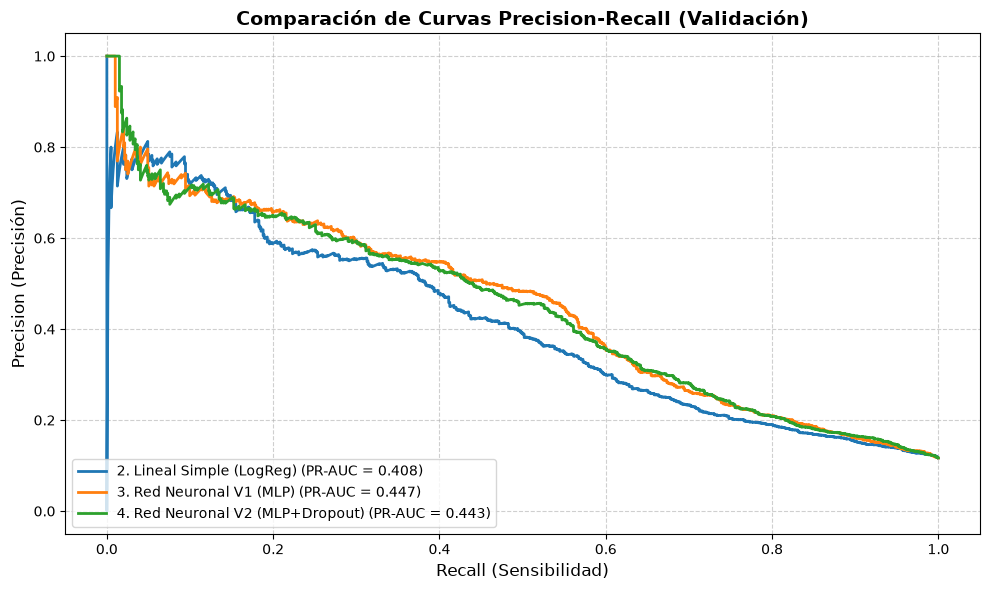

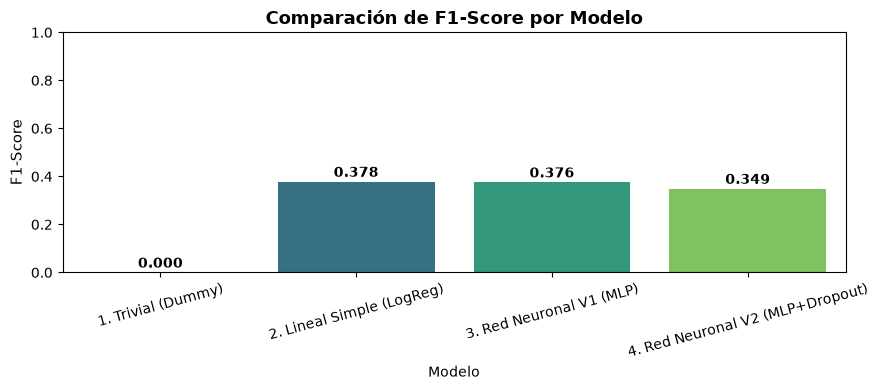

In [18]:
plt.figure(figsize=(10, 6))

# Graficar curva Precision-Recall para los modelos que tienen probabilidad
for nombre, (_, y_prob) in modelos_eval.items():
    if y_prob is not None:
        precision_c, recall_c, _ = precision_recall_curve(y_val, y_prob)
        pr_auc = auc(recall_c, precision_c)
        plt.plot(recall_c, precision_c, label=f"{nombre} (PR-AUC = {pr_auc:.3f})", linewidth=2)

plt.xlabel("Recall (Sensibilidad)", fontsize=12)
plt.ylabel("Precision (Precisión)", fontsize=12)
plt.title("Comparación de Curvas Precision-Recall (Validación)", fontsize=14, fontweight='bold')
plt.legend(loc="lower left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Gráfico de barras comparativo de F1-Score
plt.figure(figsize=(9, 4))
sns.barplot(data=df_comparativa, x="Modelo", y="F1-Score", hue="Modelo", palette="viridis", legend=False)
plt.title("Comparación de F1-Score por Modelo", fontsize=13, fontweight='bold')
plt.ylim(0, 1.0)
plt.xticks(rotation=15)
plt.ylabel("F1-Score", fontsize=11)
for index, row in df_comparativa.iterrows():
    plt.text(index, row["F1-Score"] + 0.02, f"{row['F1-Score']:.3f}", color='black', ha="center", fontweight='bold')
plt.tight_layout()
plt.show()

### Conclusiones de la Etapa 4 (Evaluación y Versionado)

1. **Evidencia frente al Desbalance**:
   - La línea base trivial obtiene un Accuracy alto pero un F1-Score y Recall nulos, evidenciando que el accuracy no es una métrica válida en este dataset desbalanceado.
2. **Desempeño de Redes Neuronales vs Modelos Lineales**:
   - Las arquitecturas MLP (V1 y V2) logran capturar relaciones no lineales en las variables del marketing bancario. La incorporación de capas de *Dropout* en la **Versión 2** ayuda a controlar la varianza en el conjunto de validación.
3. **Selección del Modelo Ganador**:
   - Con base en las métricas de validación (F1-Score y PR-AUC), se identifica la versión con mejor desempeño para pasar a la Etapa 4 (Evaluación y Versionado con su respectiva ficha JSON).